# Araba Yarışı: DQN ve PPO

In [1]:
import sys
import time
import numpy as np
import matplotlib.pyplot as plt

import gymnasium as gym
from stable_baselines3 import DQN, PPO
from stable_baselines3.common.vec_env import DummyVecEnv
from stable_baselines3.common.callbacks import BaseCallback

print(sys.executable)
print("gymnasium:", gym.__version__)

/home/emre/.pyenv/versions/3.12.9/envs/reinforcement-env/bin/python
gymnasium: 1.0.0


## 1. Ortamı inceleme

Gözlem uzayı: Box(0, 255, (96, 96, 3), uint8)
Eylem uzayı: Box([-1.  0.  0.], 1.0, (3,), float32)
Gözlem şekli: (96, 96, 3) | tür: uint8


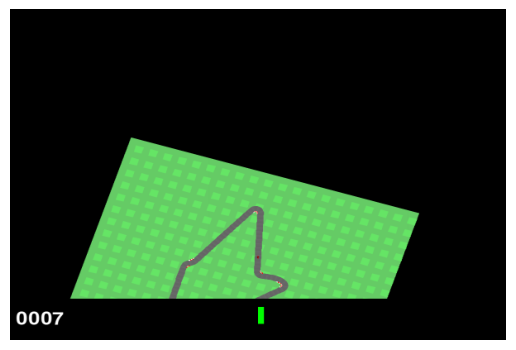

In [2]:
env = gym.make("CarRacing-v3", render_mode="rgb_array")

obs, info = env.reset(seed=42)
print("Gözlem uzayı:", env.observation_space)
print("Eylem uzayı:", env.action_space)
print("Gözlem şekli:", obs.shape, "| tür:", obs.dtype)

plt.imshow(env.render())
plt.axis("off")
plt.show()

env.close()

## 2. DQN'i doğrudan denemek
Varsayılan eylem uzayı sürekli (`Box`). DQN yalnızca ayrık (`Discrete`) uzayla çalışır.

In [3]:
env = gym.make("CarRacing-v3")
env = DummyVecEnv([lambda: env])

try:
    model = DQN("CnnPolicy", env, verbose=1)
    model.learn(total_timesteps=10_000)
except Exception as e:
    print(type(e).__name__)
    print(e)

env.close()

Using cpu device
Wrapping the env in a VecTransposeImage.
AssertionError
The algorithm only supports (<class 'gymnasium.spaces.discrete.Discrete'>,) as action spaces but Box([-1.  0.  0.], 1.0, (3,), float32) was provided


## 3. Ayrık eylem uzayı
Bu gymnasium sürümünde `continuous=False` modu eylemi float'a çevirdiği için `InvalidAction` hatası veriyor.
Bu yüzden sürekli ortamı 5 ayrık eyleme çeviren bir wrapper kullanıyoruz:
0 hiçbir şey, 1 sol, 2 sağ, 3 gaz, 4 fren.

In [4]:
class DiscreteCarRacing(gym.ActionWrapper):
    def __init__(self, env):
        super().__init__(env)
        self.action_space = gym.spaces.Discrete(5)
        self.table = np.array(
            [
                [0.0, 0.0, 0.0],
                [0.6, 0.0, 0.0],
                [-0.6, 0.0, 0.0],
                [0.0, 0.2, 0.0],
                [0.0, 0.0, 0.8],
            ],
            dtype=np.float32,
        )

    def action(self, action):
        return self.table[int(action)]


def make_env():
    return DummyVecEnv([lambda: DiscreteCarRacing(gym.make("CarRacing-v3"))])


env = make_env()
print(env.action_space)
print(env.observation_space)
env.close()

Discrete(5)
Box(0, 255, (96, 96, 3), uint8)


In [5]:
class EpisodeRewardLogger(BaseCallback):
    def __init__(self, verbose=0):
        super().__init__(verbose)
        self.episode_rewards = []
        self.episode_reward = 0

    def _on_step(self) -> bool:
        self.episode_reward += self.locals["rewards"][0]
        if self.locals["dones"][0]:
            self.episode_rewards.append(self.episode_reward)
            self.episode_reward = 0
        return True

## 4. DQN eğitimi

In [6]:
dqn_env = make_env()
dqn_model = DQN(
    "CnnPolicy",
    dqn_env,
    verbose=1,
    seed=42,
    buffer_size=30_000,
    learning_starts=5_000,
    learning_rate=1e-4,
    batch_size=64,
    train_freq=4,
    target_update_interval=1_000,
    exploration_fraction=0.3,
    exploration_final_eps=0.05,
)
dqn_logger = EpisodeRewardLogger()

start = time.time()
dqn_model.learn(total_timesteps=100_000, callback=dqn_logger)
dqn_time = time.time() - start

print(f"Eğitim süresi: {dqn_time:.1f} saniye")
print("Bölüm sayısı:", len(dqn_logger.episode_rewards))
print("Son 10 bölüm ödülü:", np.round(dqn_logger.episode_rewards[-10:], 1))

dqn_model.save("dqn_car_racing")
dqn_env.close()

Using cpu device
Wrapping the env in a VecTransposeImage.
----------------------------------
| rollout/            |          |
|    exploration_rate | 0.873    |
| time/               |          |
|    episodes         | 4        |
|    fps              | 114      |
|    time_elapsed     | 34       |
|    total_timesteps  | 4000     |
----------------------------------
----------------------------------
| rollout/            |          |
|    exploration_rate | 0.747    |
| time/               |          |
|    episodes         | 8        |
|    fps              | 63       |
|    time_elapsed     | 125      |
|    total_timesteps  | 8000     |
| train/              |          |
|    learning_rate    | 0.0001   |
|    loss             | 0.0415   |
|    n_updates        | 749      |
----------------------------------
----------------------------------
| rollout/            |          |
|    exploration_rate | 0.62     |
| time/               |          |
|    episodes         | 12      

## 5. PPO eğitimi

In [7]:
ppo_env = make_env()
ppo_model = PPO("CnnPolicy", ppo_env, verbose=1, seed=42)
ppo_logger = EpisodeRewardLogger()

start = time.time()
ppo_model.learn(total_timesteps=100_000, callback=ppo_logger)
ppo_time = time.time() - start

print(f"Eğitim süresi: {ppo_time:.1f} saniye")
print("Bölüm sayısı:", len(ppo_logger.episode_rewards))
print("Son 10 bölüm ödülü:", np.round(ppo_logger.episode_rewards[-10:], 1))

ppo_model.save("ppo_car_racing")
ppo_env.close()

Using cpu device
Wrapping the env in a VecTransposeImage.
-----------------------------
| time/              |      |
|    fps             | 83   |
|    iterations      | 1    |
|    time_elapsed    | 24   |
|    total_timesteps | 2048 |
-----------------------------
------------------------------------------
| time/                   |              |
|    fps                  | 65           |
|    iterations           | 2            |
|    time_elapsed         | 62           |
|    total_timesteps      | 4096         |
| train/                  |              |
|    approx_kl            | 0.0153146945 |
|    clip_fraction        | 0.201        |
|    clip_range           | 0.2          |
|    entropy_loss         | -1.6         |
|    explained_variance   | 0.000981     |
|    learning_rate        | 0.0003       |
|    loss                 | 0.166        |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.0187      |
|    value_loss           | 0.71         |
-

## 6. Değerlendirme
Her ajan aynı 5 pistte (aynı seed'ler) deterministik politikayla sürülür.

In [8]:
def run_episode(model, seed, render=False):
    eval_env = DiscreteCarRacing(gym.make("CarRacing-v3", render_mode="rgb_array"))
    obs, _ = eval_env.reset(seed=seed)
    total = 0.0
    frames = []
    step = 0
    done = False
    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, _ = eval_env.step(action)
        total += reward
        step += 1
        done = terminated or truncated
        if render and step % 100 == 0:
            frames.append(eval_env.render())
    eval_env.close()
    return total, frames


seeds = [1, 2, 3, 4, 5]
dqn_scores = [run_episode(dqn_model, s)[0] for s in seeds]
ppo_scores = [run_episode(ppo_model, s)[0] for s in seeds]

print("DQN:", np.round(dqn_scores, 1), "ortalama:", round(np.mean(dqn_scores), 1))
print("PPO:", np.round(ppo_scores, 1), "ortalama:", round(np.mean(ppo_scores), 1))

DQN: [267.3 174.6 324.4 474.5 243.5] ortalama: 296.9
PPO: [347.3 129.9 848.3 365.5 182.7] ortalama: 374.7


## 7. Sürüşün görsel gözlemi

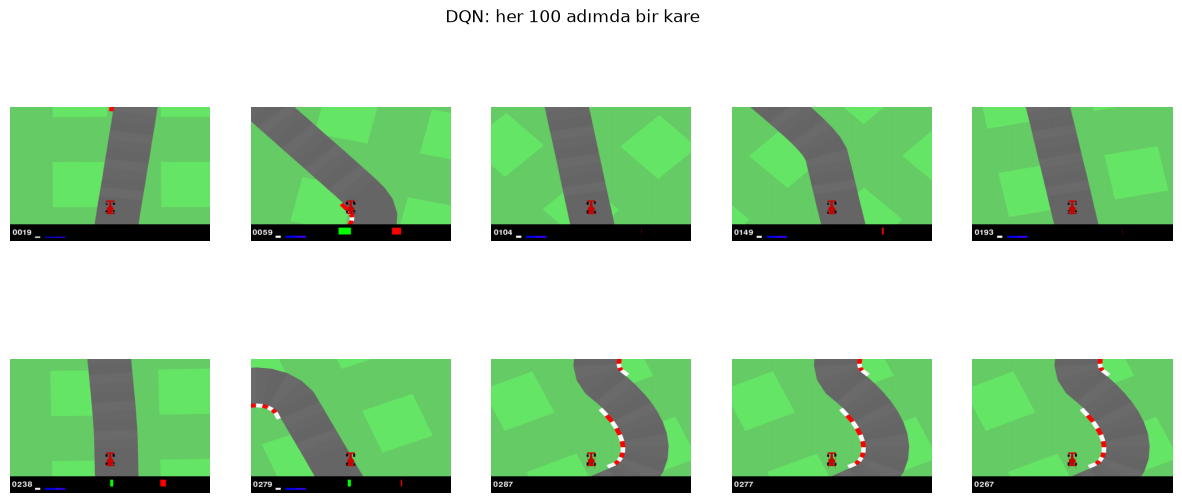

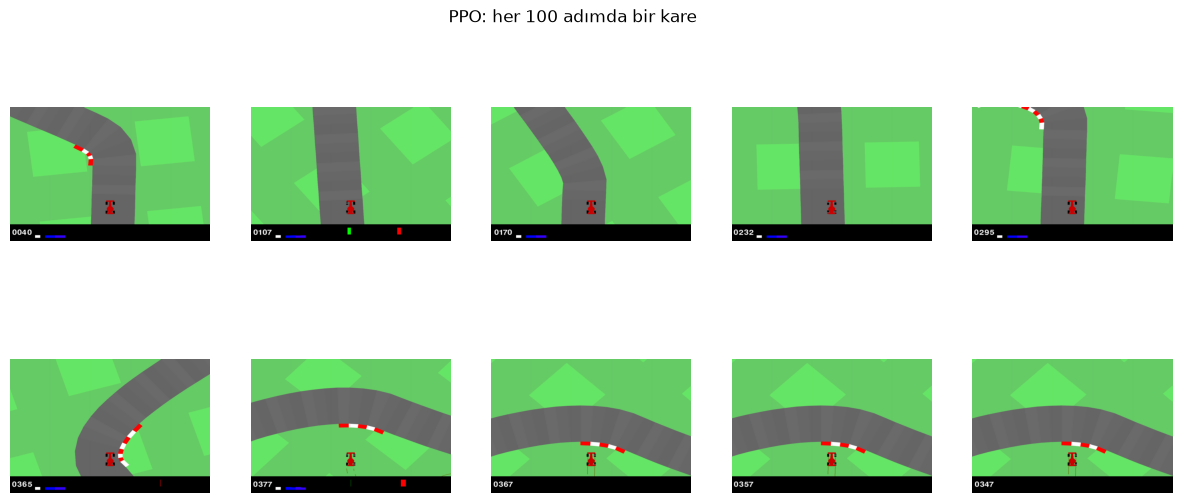

In [9]:
def show_frames(frames, title):
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    for ax, frame in zip(axes.ravel(), frames):
        ax.imshow(frame)
        ax.axis("off")
    fig.suptitle(title)
    plt.show()


_, dqn_frames = run_episode(dqn_model, seed=1, render=True)
_, ppo_frames = run_episode(ppo_model, seed=1, render=True)
show_frames(dqn_frames, "DQN: her 100 adımda bir kare")
show_frames(ppo_frames, "PPO: her 100 adımda bir kare")

## 8. Karşılaştırma

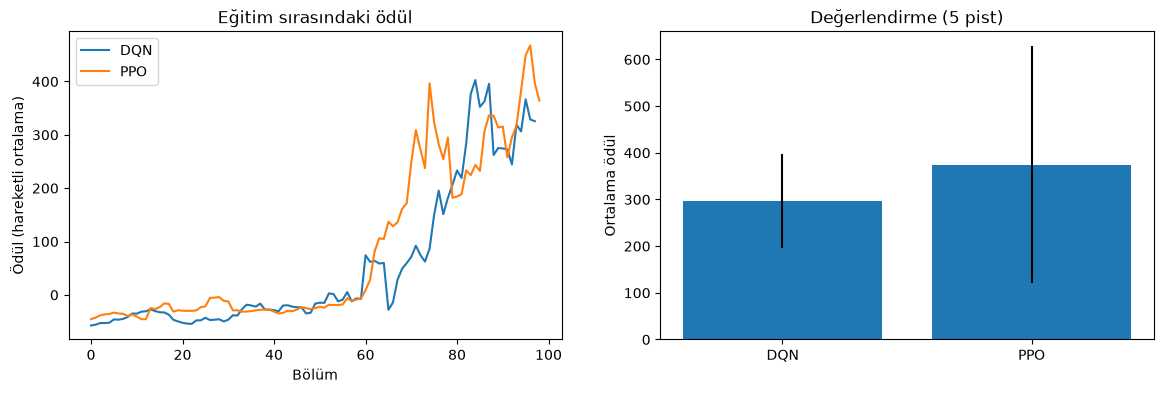

Eğitim süresi - DQN: 3326 sn, PPO: 1919 sn


In [10]:
def moving_average(values, window=5):
    values = np.array(values)
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window) / window, mode="valid")


fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(moving_average(dqn_logger.episode_rewards), label="DQN")
axes[0].plot(moving_average(ppo_logger.episode_rewards), label="PPO")
axes[0].set_xlabel("Bölüm")
axes[0].set_ylabel("Ödül (hareketli ortalama)")
axes[0].set_title("Eğitim sırasındaki ödül")
axes[0].legend()

axes[1].bar(
    ["DQN", "PPO"],
    [np.mean(dqn_scores), np.mean(ppo_scores)],
    yerr=[np.std(dqn_scores), np.std(ppo_scores)],
)
axes[1].set_ylabel("Ortalama ödül")
axes[1].set_title("Değerlendirme (5 pist)")
plt.show()

print(f"Eğitim süresi - DQN: {dqn_time:.0f} sn, PPO: {ppo_time:.0f} sn")

In [1]:
import numpy as np
import gymnasium as gym
from stable_baselines3 import DQN, PPO


class DiscreteCarRacing(gym.ActionWrapper):
    def __init__(self, env):
        super().__init__(env)
        self.action_space = gym.spaces.Discrete(5)
        self.table = np.array(
            [
                [0.0, 0.0, 0.0],
                [0.6, 0.0, 0.0],
                [-0.6, 0.0, 0.0],
                [0.0, 0.2, 0.0],
                [0.0, 0.0, 0.8],
            ],
            dtype=np.float32,
        )

    def action(self, action):
        return self.table[int(action)]


dqn_model = DQN.load("dqn_car_racing")
ppo_model = PPO.load("ppo_car_racing")
seeds = [1, 2, 3, 4, 5]


def episode_info(model, seed):
    eval_env = DiscreteCarRacing(gym.make("CarRacing-v3"))
    obs, _ = eval_env.reset(seed=seed)
    total, step, done = 0.0, 0, False
    while not done:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, _ = eval_env.step(action)
        total += reward
        step += 1
        done = terminated or truncated
    eval_env.close()
    return round(total, 1), step, terminated


for name, model in [("DQN", dqn_model), ("PPO", ppo_model)]:
    for s in seeds:
        print(name, s, episode_info(model, s))

DQN 1 (267.3, 1000, False)
DQN 2 (174.6, 1000, False)
DQN 3 (324.4, 1000, False)
DQN 4 (474.5, 1000, False)
DQN 5 (243.5, 1000, False)
PPO 1 (347.3, 1000, False)
PPO 2 (129.9, 1000, False)
PPO 3 (848.3, 1000, False)
PPO 4 (365.5, 1000, False)
PPO 5 (182.7, 1000, False)


## 9. Yorum

- **Kurulum:** `CarRacing-v3` varsayılan olarak sürekli eylem uzayı (direksiyon, gaz, fren) kullanıyor. DQN bu uzayda çalışmadı (`AssertionError`: `Discrete` bekleniyor). Bu yüzden sürekli ortamı 5 ayrık eyleme çeviren bir sarmalayıcı yazıldı (hiçbir şey, sol, sağ, gaz, fren). İki ajan da `CnnPolicy` ile 100.000 adım eğitildi.

- **Eğitim:** DQN 3326 sn (yaklaşık 30 adım/sn), PPO 1919 sn (yaklaşık 52 adım/sn) sürdü, yani PPO aynı adım sayısı için yaklaşık %42 daha kısa sürdü. İki ajanın da eğitim ödülü yaklaşık 55-60 bölüm boyunca -50 ile 0 arasında kaldı, sonra yükseldi. Son 10 eğitim bölümünün ortalaması DQN için 285.0, PPO için 340.7 (eğitim sırasındaki keşif ve rastgele eylemler dahil).

- **Değerlendirme (5 pist, deterministik politika):** DQN: 267.3, 174.6, 324.4, 474.5, 243.5 (ortalama 296.9, std 101). PPO: 347.3, 129.9, 848.3, 365.5, 182.7 (ortalama 374.7, std 254). PPO 2 pistte, DQN 3 pistte önde.

- **Tur tamamlama:** 10 bölümün hepsi 1000 adımda `terminated=False` ile zaman sınırında bitti. Hiçbir bölüm tur tamamlayarak erken bitmedi ve hiçbir araç oyun alanının dışına çıkmadı. En iyi bölüm PPO pist 3 (848.3): ödül formülüne göre pistin yaklaşık %94.8'i gezilmiş, %95 tur eşiğinin hemen altında. Diğer bölümlerde gezilen oran yaklaşık %23-57. Yani ajanlar yolda kalıp ilerleyebiliyor, ama hiçbiri turu tamamlamadı.

- **Sürüş kareleri (pist 1):** İki ajan da bir süre pistte ilerledi, sonra durdu. DQN bir virajda, PPO virajın dışında çimde kaldı. Skor sayacı son karelerde 100 adımda 10 puan düştü (kare başı -0.1), bu araçların durduğuyla uyumlu.

- **Karşılaştırma:** PPO'nun ortalaması daha yüksek, ama bu büyük ölçüde tek bir pistten geliyor. PPO'nun 848.3'lük bölümü çıkarılınca ortalamalar PPO 256.4, DQN 290.0 oluyor. Beş pist ve tek eğitim çalıştırmasıyla bir ajanın üstün olduğu söylenemez. Net olan fark eğitim hızı: PPO daha hızlı.

- **Sınırlılıklar:** Tek tohum (42), 100.000 adım (ortamın çözüm eşiği 900), ayrık eylem tablosu (gaz 0.2, direksiyon ±0.6) ve hiperparametreler ayarlanmadı. Sonuçların başka tohumlarda tekrar edip etmediğini denemedik. Değerlendirme yalnızca 5 pistte yapıldı.

- **Genel değerlendirme:** Eğitim süresi arttıkça (10.000 adımlık ilk MlpPolicy denemesinde ortalama ödül yaklaşık -54 idi, ama o denemede politika türü de farklıydı) iki ajan da anlamlı biçimde ilerlemeyi öğrendi. Tam tur için daha uzun eğitim ya da ayrık eylem tablosunun ve takılmanın incelenmesi gerekecek.